<a href="https://colab.research.google.com/github/bounouarafarah/OIBSIP/blob/main/DataScience-Task3-SalesPrediction/sales_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns

url = "https://raw.githubusercontent.com/justmarkham/scikit-learn-videos/master/data/Advertising.csv"
df = pd.read_csv(url, index_col=0)
df.columns = ["TV", "Radio", "Newspaper", "Sales"]

print(df.shape)
print(df.isnull().sum())
df.describe()

(200, 4)
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64


,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14.022500
std,85.854236,14.846809,21.778621,5.217457
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,10.375000
50%,149.750000,22.900000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000


## Observations: data and relationships

- The dataset has 200 rows and 4 columns (TV, Radio, Newspaper, Sales) with no missing values. The average sales value is about 14.0, and TV is by far the biggest budget (mean about 147).
- Sales increase clearly with TV spending and with Radio spending. The relationship with Newspaper is much more scattered.
- Correlation with Sales: TV 0.78, Radio 0.58, Newspaper 0.23. TV and Radio are almost independent (0.055), so each one brings its own information.
- Newspaper is weakly linked to Sales, and its correlation with Radio (0.35) suggests that part of its apparent effect may come from Radio.

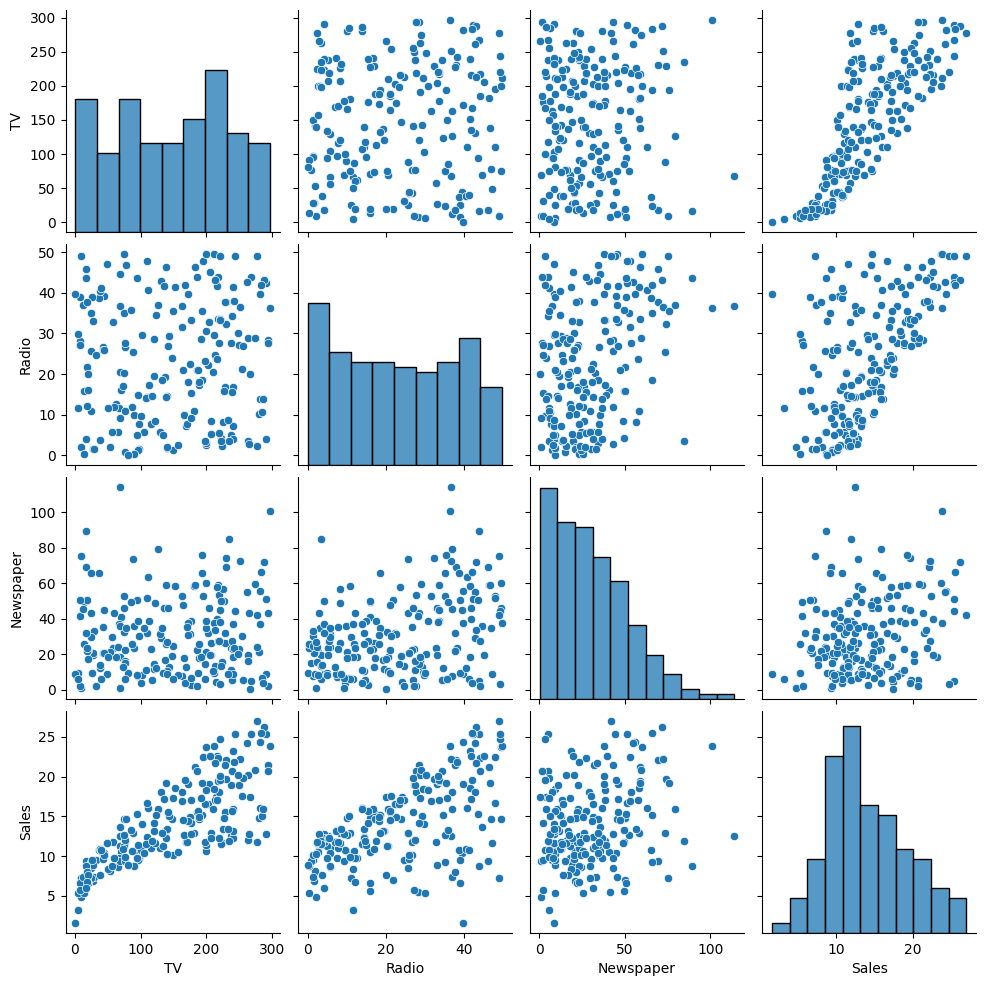

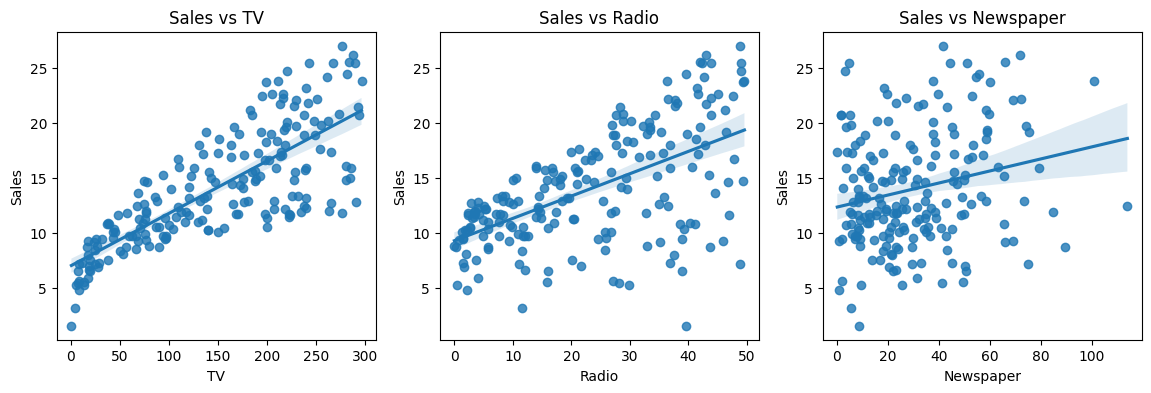

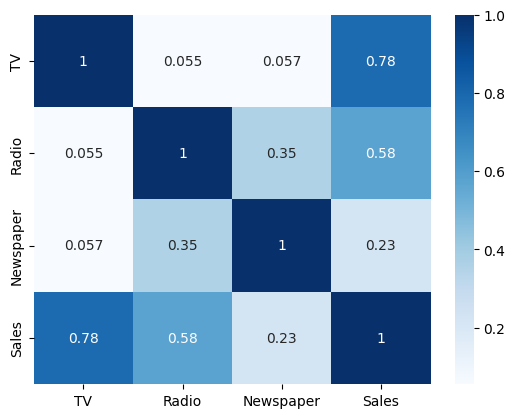

In [6]:
sns.pairplot(df); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["TV", "Radio", "Newspaper"]):
    sns.regplot(data=df, x=col, y="Sales", ax=ax)
    ax.set_title(f"Sales vs {col}")
plt.show()

sns.heatmap(df.corr(), annot=True, cmap="Blues"); plt.show()

## Observations: model comparison

| Model | MAE | RMSE | R2 |
|---|---|---|---|
| Linear Regression | 1.461 | 1.782 | 0.899 |
| Random Forest | 0.620 | 0.769 | 0.981 |

- Random Forest is clearly better: its average error (MAE) is more than twice smaller (0.62 vs 1.46 units of sales) and it explains 98.1% of the variance versus 89.9%.
- A likely reason is that the link between TV and Sales is not perfectly a straight line, which a linear model cannot capture. Random Forest can.
- The test set only has 40 rows, so these scores should be read with some caution.

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X = df[["TV", "Radio", "Newspaper"]]; y = df["Sales"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

models = {"Linear Regression": LinearRegression(),
          "Random Forest": RandomForestRegressor(random_state=42)}
rows, preds = [], {}
for name, m in models.items():
    m.fit(X_train, y_train); p = m.predict(X_test); preds[name] = p
    rows.append({"Model": name,
                 "MAE": mean_absolute_error(y_test, p),
                 "RMSE": np.sqrt(mean_squared_error(y_test, p)),
                 "R2": r2_score(y_test, p)})
pd.DataFrame(rows).round(3)

,Model,MAE,RMSE,R2
0,Linear Regression,1.461,1.782,0.899
1,Random Forest,0.620,0.769,0.981


## Observations: residuals and channel impact

- Residuals: [the points are randomly spread around 0, so there is no obvious systematic error] OR [the points show a pattern (curve or funnel), so the model misses some structure].
- Linear Regression coefficients: Radio 0.189, TV 0.045, Newspaper 0.003. Per unit of budget, Radio brings the biggest increase in sales, and Newspaper almost nothing.
- Random Forest feature importance: TV 0.625, Radio 0.362, Newspaper 0.013. Overall, TV explains most of the variation in sales.
- **Conclusion:** TV has the highest overall impact on sales (highest correlation and importance), while Radio is the most efficient per unit spent. Newspaper has almost no impact and is the first budget to cut. The best model is Random Forest.

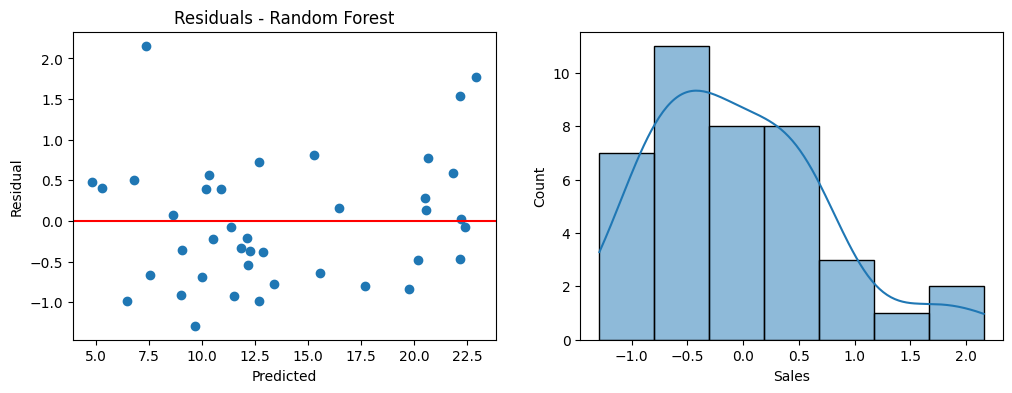

TV           0.045
Radio        0.189
Newspaper    0.003
dtype: float64
TV           0.625
Radio        0.362
Newspaper    0.013
dtype: float64


In [8]:
best = max(rows, key=lambda r: r["R2"])["Model"]
res = y_test - preds[best]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(preds[best], res); ax[0].axhline(0, color="red")
ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("Residual"); ax[0].set_title(f"Residuals - {best}")
sns.histplot(res, kde=True, ax=ax[1]); plt.show()

print(pd.Series(models["Linear Regression"].coef_, index=X.columns).round(3))
print(pd.Series(models["Random Forest"].feature_importances_, index=X.columns).round(3))